In [92]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

In [ ]:
property_df = pd.read_csv("../data/listings.csv")


In [39]:
sample_df, test_df = train_test_split(property_df, test_size=0.1, random_state=0)
train_df, val_df = train_test_split(sample_df, test_size=0.3, random_state=0)

In [ ]:
from geopy.distance import geodesic

abnb = (51.494600, -0.243020)
print(geodesic(cx_lat_lon, abnb).kilometers)

train_df[['id','latitude','longitude','neighbourhood_cleansed']].head(25)

8.345289906258511


,id,latitude,longitude,neighbourhood_cleansed
70145,1170234975129016542,51.494600,-0.243020,Hammersmith and Fulham
18816,22627388,51.484250,0.029870,Greenwich
21386,25770489,51.523150,-0.139440,Camden
87363,1366544630604141171,51.604964,0.090786,Redbridge
70079,1169548984442372834,51.475830,-0.019340,Greenwich
23962,29077076,51.548630,-0.058240,Hackney
85469,1346578403552934905,51.556540,0.001860,Waltham Forest
35424,47840872,51.542800,-0.218820,Brent
77448,1259946609403889981,51.482724,-0.060038,Southwark
57384,970184315961639599,51.475942,-0.071178,Southwark


<Axes: xlabel='longitude', ylabel='latitude'>

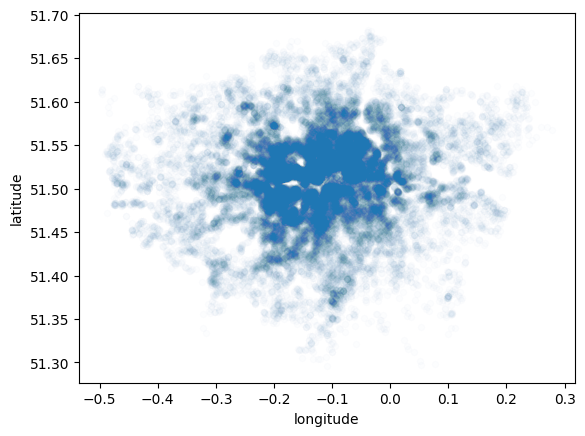

In [47]:
train_df[['latitude','longitude']].plot(x='longitude',y='latitude', kind='scatter', alpha=0.01)

In [ ]:
from sklearn.cluster import MiniBatchKMeans

X = train_df[['longitude','latitude']]
print(len(X))

60889


In [ ]:
kmeans = MiniBatchKMeans(n_clusters=40, random_state=0, batch_size=256).fit(X)
classes = kmeans.predict(X)

<Axes: xlabel='longitude', ylabel='latitude'>

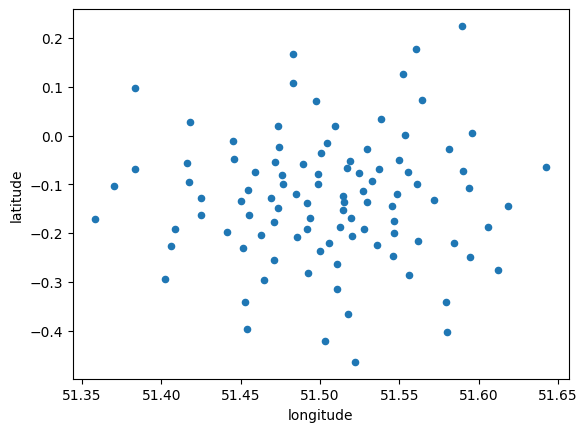

In [116]:
pd.DataFrame(kmeans.cluster_centers_, columns=['longitude','latitude']).plot(x='longitude',y='latitude',kind='scatter')

In [117]:
train_df['cluster_class_temp'] = classes

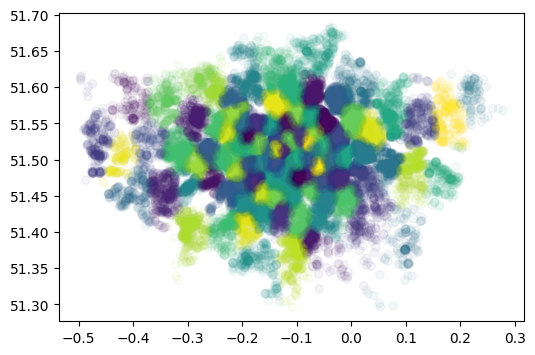

In [118]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
scatter = plt.scatter(train_df['longitude'], train_df['latitude'], c=train_df['cluster_class_temp'].astype('category').cat.codes, cmap='viridis', alpha=0.05)



In [ ]:
join_cols = ['id','host_id']
host_features = ['host_since','host_location','host_response_time','host_response_rate', 'host_acceptance_rate','host_is_superhost']
property_features = [
    'cluster_class', 'neighbourhood_cleansed', 'property_type_cleansed', 
    'room_type', 'accommodates', 'bathrooms', 'bathrooms_text',
    'bedrooms', 'beds', 'amenities', 'price', 'license', 'instant_bookable']
reviews_features = [
    'number_of_reviews', 'number_of_review_ltm', 'number_of_reviews_l30d', 
    'first_review', 'last_review', 'review_scores_rating', 
    'review_scores_accuracy', 'review_scores_cleanliness', 
    'review_scores_checkin', 'review_scores_communication', 
    'review_scores_location', 'review_scores_value', 'license', 'instant_bookable'
]



In [72]:
train_df[join_cols+property_features]

for p in property_features:
    print(p)
    print(train_df[p].unique())
# train_df.columns

cluster_class
[11 12 19 23  7 17 21 29 36 33 27 38  4 10 13 25  1 22 24  0 18 39 30 28
  8 31  5 20 37  2 35 15 34 16 32  9  6  3 26 14]
neighbourhood_cleansed
['Hammersmith and Fulham' 'Greenwich' 'Camden' 'Redbridge' 'Hackney'
 'Waltham Forest' 'Brent' 'Southwark' 'City of London' 'Lambeth' 'Bromley'
 'Newham' 'Westminster' 'Kensington and Chelsea' 'Tower Hamlets' 'Croydon'
 'Ealing' 'Sutton' 'Merton' 'Barnet' 'Wandsworth' 'Islington' 'Hillingdon'
 'Lewisham' 'Havering' 'Harrow' 'Hounslow' 'Enfield'
 'Richmond upon Thames' 'Bexley' 'Haringey' 'Barking and Dagenham'
 'Kingston upon Thames']
neighbourhood_group_cleansed
[nan]
property_type
['Entire rental unit' 'Private room in rental unit' 'Entire townhouse'
 'Entire home' 'Private room in home' 'Entire condo'
 'Entire serviced apartment' 'Private room in townhouse' 'Entire loft'
 'Private room in condo' 'Entire bungalow' 'Private room in guesthouse'
 'Shared room in hostel' 'Room in hotel' 'Houseboat' 'Entire guesthouse'
 'Private ro

In [ ]:
def clean_property_type(x: str):
    if x.startswith("Entire"):
        x = x.replace("Entire ", "")
        return x
    if x.startswith("Private room in"):
        x = x.replace("Private room in ", "")
        return x
    if x.startswith("Shared room in"):
        x = x.replace("Shared room in ", "")
        return x
    if x.startswith("Room in"):
        x = x.replace("Room in ", "")
        return x
    return x

cx_lat_lon = (51.5081, -0.1248)

train_df['property_type_cleansed'] = train_df.property_type.apply(clean_property_type).str.capitalize()
train_df['distance_from_cx_km'] = train_df.apply(
    lambda row: geodesic(cx_lat_lon, (row["latitude"], row["longitude"])).kilometers,
    axis=1
)

with pd.option_context('display.max_rows',None):
    display(
        train_df.groupby(
            ['property_type', 'room_type','property_type_cleansed']
        ).count().sort_values(by=['id'], ascending=False)[['id']])


,,,id
property_type,room_type,property_type_cleansed,
Entire rental unit,Entire home/apt,Rental unit,25572
Private room in rental unit,Private room,Rental unit,9237
Private room in home,Private room,Home,7465
Entire home,Entire home/apt,Home,5676
Entire condo,Entire home/apt,Condo,5290
Private room in condo,Private room,Condo,2070
Entire serviced apartment,Entire home/apt,Serviced apartment,1168
Private room in townhouse,Private room,Townhouse,758
Entire townhouse,Entire home/apt,Townhouse,705
